In [35]:
import matplotlib.pyplot as plt
import numpy as np
from glob import glob
import time
import os

import psutil

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, TensorDataset


from typing import Tuple
import random


from keras.utils import img_to_array , load_img , plot_model

import cv2

import seaborn as sns

sns.set_style("dark")



In [36]:
#import glob
import matplotlib.colors
labels_cmap = matplotlib.colors.ListedColormap(["#000000", "#A9A9A9",
        "#8B8680", "#D3D3D3", "#FFFFFF"])

In [24]:
ram_gb = psutil.virtual_memory().total / 1e9
print('Your runtime has {:.1f} gigabytes of available RAM\n'.format(ram_gb))

if ram_gb < 20:
  print('Not using a high-RAM runtime')
else:
  print('You are using a high-RAM runtime!')

Your runtime has 13.6 gigabytes of available RAM

Not using a high-RAM runtime


In [25]:
!pip install torchmetrics

In [26]:
from google.colab import drive
drive.mount( '/content/drive',force_remount=True )

Mounted at /content/drive


In [27]:
# Dossier où sauvegarder les modèles
SAVE_DIR = "/content/drive/MyDrive/Pix2PixGANSatelliteMap/models"
os.makedirs(SAVE_DIR, exist_ok=True)

In [28]:
# ************************************************
#  Device & Hyperparameters
# ************************************************
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

IMAGE_SIZE = 256
BATCH_SIZE = 8
EPOCHS = 500
LR = 2e-4
BETA1 = 0.5
#LAMBDA_L1 = 100.0
#LAMBDA_L1 = 50.0     # au lieu de 100 , couleurs trop délavées
LAMBDA_L1 = 20.0

#en terme d'intervalles d'epochs
INTERVALLE_SAUVEGARDE_MODELES = 100

Using device: cuda


**Fonctions liées aux sauvegardes et chargement modèles**

In [29]:
# Fonction pour obtenir le chemin complet d'un fichier
def get_model_path(filename):
    return os.path.join(SAVE_DIR, filename)

In [30]:
def save_models(generator, discriminator, epoch, prefix="pix2pix"):
    """
    Sauvegarde les poids du générateur et du discriminateur.

    Args:
        generator     : modèle Generator
        discriminator : modèle PatchDiscriminator
        epoch         : numéro d'époque (pour le nom du fichier)
        prefix        : préfixe du nom de fichier (ex: 'pix2pix', 'landcover')
    """
    checkpoint = {
        'epoch': epoch,
        'generator_state_dict': generator.state_dict(),
        'discriminator_state_dict': discriminator.state_dict(),
        # Optionnel : on peut aussi sauvegarder les optimiseurs si on veut reprendre exactement
        #'optimizer_G_state_dict': optim_G.state_dict(),
        #'optimizer_D_state_dict': optim_D.state_dict(),
    }

    filename = f"{prefix}_epoch_{epoch:04d}.pth"
    path = get_model_path(filename)

    torch.save(checkpoint, path)
    print(f"Modèles sauvegardés → {path}")

In [31]:
def load_models(generator, discriminator, epoch, prefix="pix2pix", strict=True):
    """
    Charge les poids sauvegardés dans les modèles.

    Retourne True si le chargement a réussi, False sinon.
    """
    filename = f"{prefix}_epoch_{epoch:04d}.pth"
    path = get_model_path(filename)

    if not os.path.exists(path):
        print(f"Fichier non trouvé : {path}")
        return False

    try:
        checkpoint = torch.load(path, map_location=device)

        generator.load_state_dict(checkpoint['generator_state_dict'], strict=strict)
        discriminator.load_state_dict(checkpoint['discriminator_state_dict'], strict=strict)

        print(f"Modèles chargés avec succès depuis l'époque {checkpoint['epoch']}")
        print(f"Fichier : {path}")
        return True

    except Exception as e:
        print(f"Erreur lors du chargement : {e}")
        return False

**Reading the data, and seeing the training images**

The dataset contains satellite images along with the annotated images that look like a map version of our satellite image. The satellite and the target images are both given in one single image side by side.

In [32]:
#Landcover
#DATA_ROOT = "../input/landcoverai"
googledrive_workspace_directory = "/content/drive/MyDrive/Pix2PixGANSatelliteMap"
#images_directory = googledrive_workspace_directory + '/archive/images/'
images_directory = '/content/drive/MyDrive/Pix2PixGANSatelliteMap/LandCover_ai/archive/images/'
utils_directory = '/content/drive/MyDrive/Pix2PixGANSatelliteMap/code/utils.py'

**Image Splitting**

In [ ]:
#IMPORTER utils.py à la racine de MyDrive ou repertoire de base de l'arborescence du menu fichier Collab
#from utils import split_images

#split_images(TARGET_SIZE = IMAGE_SIZE)

images list 41


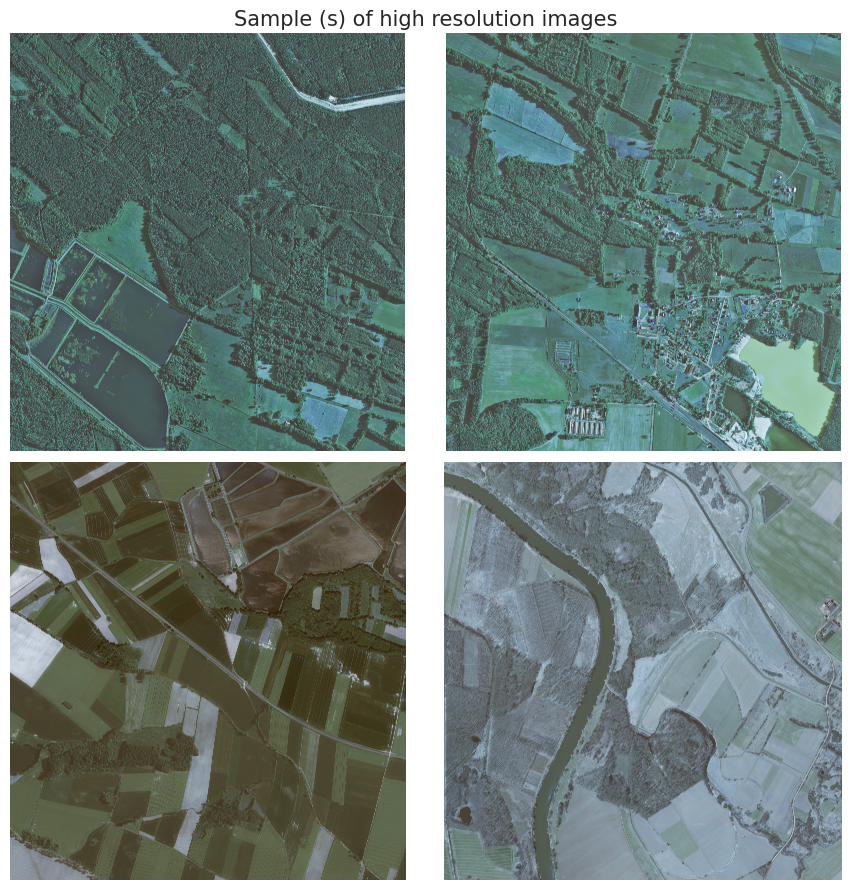

In [ ]:
#LandCover
images_list = list(glob(os.path.join(images_directory, "*.tif")))

print('images list', len(images_list))

samples = [0,1,2,3]
fig, ax = plt.subplots(figsize = (9,9), nrows = 2, ncols =2)
for i, sample in enumerate(samples):
    r,c = divmod(i,2)
    ax[r,c].imshow(cv2.imread(images_list[sample])/255)
    ax[r,c].axis("off")
plt.suptitle("Sample (s) of high resolution images", fontsize = 15)
plt.tight_layout(pad=0.8)
plt.savefig("Samples.png")
plt.show()

**Visualization exemple image/mask splittées**

TESTTESTTEST
/content/drive/MyDrive/Pix2PixGANSatelliteMap/output/M-34-55-B-b-4-1_527.jpg
/content/drive/MyDrive/Pix2PixGANSatelliteMap/output/M-34-55-B-b-4-1_528.jpg
/content/drive/MyDrive/Pix2PixGANSatelliteMap/output/M-34-55-B-b-4-1_545.jpg
/content/drive/MyDrive/Pix2PixGANSatelliteMap/output/M-34-55-B-b-4-1_548.jpg
/content/drive/MyDrive/Pix2PixGANSatelliteMap/output/M-34-55-B-b-4-1_557.jpg
/content/drive/MyDrive/Pix2PixGANSatelliteMap/output/M-34-55-B-b-4-1_532.jpg
/content/drive/MyDrive/Pix2PixGANSatelliteMap/output/M-34-55-B-b-4-1_533.jpg
/content/drive/MyDrive/Pix2PixGANSatelliteMap/output/M-34-55-B-b-4-1_534.jpg


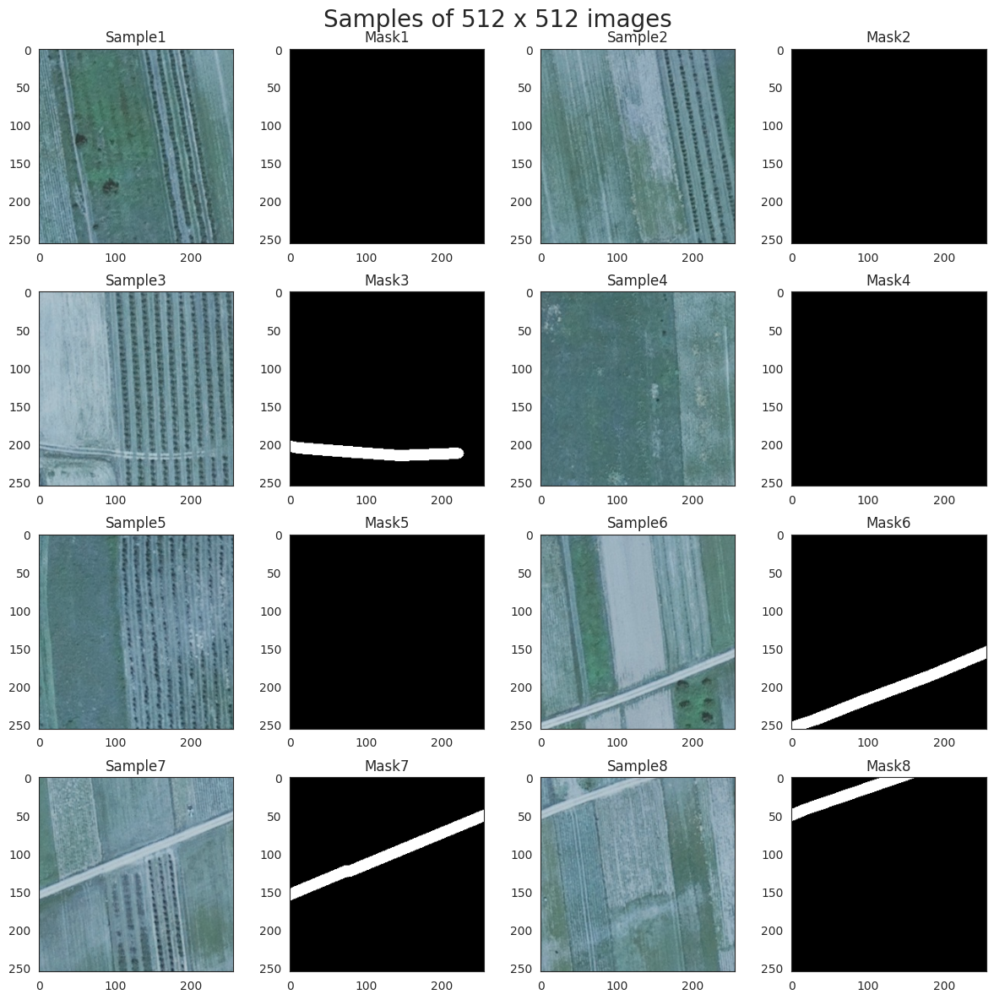

In [12]:
#IMPORTER utils.py à la racine de MyDrive ou repertoire de base de l'arborescence du menu fichier Collab
from utils import visualize_dataset

visualize_dataset(num_samples = 8, w = 12, h = 12, pad = 1.4,
                 save_title = "Visualize_dataset", indices = [0,1,17,20,29,5,6,7])

**Dataset creation**

In [33]:
#train directory
train_directory = '/content/drive/MyDrive/Pix2PixGANSatelliteMap/output'


In [ ]:
images_nombre = sorted(glob(train_directory + "/*.jpg"))
print('images nombres ', len(images_nombre))

KeyboardInterrupt: 

In [ ]:
del images_nombre

NameError: name 'images_nombre' is not defined

In [37]:
# *************************************************
#  Load & Preprocess (numpy → torch tensors)
# *************************************************
#Landcover

num_images = 800  #ok working with 10, 50, 200
#num_images = 4000  #ok working with 10, 50, 200
IMAGE_SIZE = 256
images_splitted = sorted(glob(train_directory + "/*.jpg"))[:num_images]
print('images splitted length ', len(images_splitted))

masks_splitted = sorted(glob(train_directory + "/*.png"))[:num_images]

print('masks splitted length ', len(masks_splitted))

#matrice numpy init a zero avec toutes les images , 3 canaux
sat_images  = np.zeros((len(images_splitted), IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.float32)
map_masks   = np.zeros((len(masks_splitted),  IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.float32)


#resize = transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))

#transformation images splitées en tableau
for i, path in enumerate(images_splitted):
  img = cv2.imread(path)[..., ::-1]           # BGR → RGB
  #img = cv2.resize(img, (IMAGE_SIZE, IMAGE_SIZE))
  sat_images[i] = img.astype(np.float32) / 255.0

#transformation masks splités en tableau
for i, path in enumerate(masks_splitted):
    msk = cv2.imread(path)[..., ::-1]
    #msk = cv2.resize(msk, (IMAGE_SIZE, IMAGE_SIZE))
    map_masks[i] = msk.astype(np.float32) / 255.0

# Pix2Pix convention: condition (input) = map, target = satellite image
condition = torch.from_numpy(map_masks).permute(0, 3, 1, 2)     # N,H,W,C → N,C,H,W
target    = torch.from_numpy(sat_images).permute(0, 3, 1, 2)
target = target * 2.0 - 1.0                                        # [0,1] → [-1,1]   # pour ameliorer couleur

dataset = TensorDataset(condition, target)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)


images splitted length  800
masks splitted length  800


**Creating the GAN Generator**

The generator in the Pix2Pix GAN is a **U-net**

In [38]:
#Landcover
# architecture inspired from github Pix2Pix
#TODO replace 64 by start-filters
""" générateur de type Unet """
class Generator(nn.Module):
    def __init__(self, in_channels=3, out_channels=3, start_filters=64 ):
        super().__init__()

        #********* couches descendantes

        #etage 6 global - 1ere couche en descente
        self.down1 = nn.Sequential(
            nn.Conv2d(in_channels, start_filters, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True)
        )

        #etage 5 global - 2eme couche en descente
        self.down2 = nn.Sequential(
            nn.Conv2d(start_filters, start_filters*2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(start_filters*2),
            nn.LeakyReLU(0.2, inplace=True)
        )

        #etage 4 global - 3eme couche en descente
        self.down3 = nn.Sequential(
            nn.Conv2d(start_filters*2, start_filters*4, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(start_filters*4),
            nn.LeakyReLU(0.2, inplace=True)
        )

        #etage 3 global - 4eme couche en descente
        self.down4 = nn.Sequential(
            nn.Conv2d(start_filters*4, start_filters*8, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(start_filters*8),
            nn.LeakyReLU(0.2, inplace=True)
        )

        #etage 2 global - 5eme couche en descente
        self.down5 = nn.Sequential(
            nn.Conv2d(start_filters*8, start_filters*8, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(start_filters*8),
            nn.LeakyReLU(0.2, inplace=True)
        )

        #etage 1 global - 6eme couche en descente
        self.down6 = nn.Sequential(
            nn.Conv2d(start_filters*8, start_filters*8, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(start_filters*8),
            nn.LeakyReLU(0.2, inplace=True)
        )

        #************ Bottleneck - couche la plus profonde du UNET
        self.bottleneck = nn.Sequential(
            nn.Conv2d(start_filters*8, start_filters*8, kernel_size=4, stride=2, padding=1, bias=False),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(start_filters*8, start_filters*8, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(start_filters*8),
            nn.ReLU(inplace=True),
        )

        #********* couches remontantes
        #etage 1 global - 1ere couche en remontée - avec skip connection 6eme couche descente

        self.up1 = nn.Sequential(
            nn.ConvTranspose2d(start_filters*8 * 2, start_filters*8, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(start_filters*8),
            nn.ReLU(inplace=True),
        )

        #etage 2 global - 2eme couche en remontée - avec skip connection 5eme couche descente
        self.up2 = nn.Sequential(
            nn.ConvTranspose2d(start_filters*8 * 2, start_filters*8, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(start_filters*8),
            nn.ReLU(inplace=True),
        )

        #etage 3 global - 3eme couche en remontée - avec skip connection 4eme couche descente
        self.up3 = nn.Sequential(
            nn.ConvTranspose2d(start_filters*8 * 2, start_filters*4, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(start_filters*4),
            nn.ReLU(inplace=True),
        )

        #etage 4 global - 4eme couche en remontée - avec skip connection 3eme couche descente
        self.up4 = nn.Sequential(
            nn.ConvTranspose2d(start_filters*4 * 2, start_filters*2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(start_filters*2),
            nn.ReLU(inplace=True),
        )

        #etage 5 global - 5eme couche en remontée - avec skip connection 2eme couche descente
        self.up5 = nn.Sequential(
            nn.ConvTranspose2d(start_filters*2 * 2, start_filters, 4, 2, 1, bias=False),
            nn.BatchNorm2d(start_filters),
            nn.ReLU(inplace=True),
        )

        #etage 6 global - 6eme couche en remontée - avec skip connection 1ere couche descente
        self.up6 = nn.Sequential(
            nn.ConvTranspose2d(start_filters * 2, out_channels, 4, 2, 1),
            nn.Tanh()
        )


    def forward(self, x):
        # Encodeur (on sauvegarde la skip à chaque "étage" pour la concatener
        # à la couche de remontée correspondante )
        d1 = self.down1(x)       # 64
        d2 = self.down2(d1)      # 128
        d3 = self.down3(d2)      # 256
        d4 = self.down4(d3)      # 512
        d5 = self.down5(d4)      # 512
        d6 = self.down6(d5)      # 512

        # Bottleneck
        b = self.bottleneck(d6)

        # Decodeur + concatenation skips
        u1 = self.up1(torch.cat([b, d6], dim=1))
        u2 = self.up2(torch.cat([u1, d5], dim=1))
        u3 = self.up3(torch.cat([u2, d4], dim=1))
        u4 = self.up4(torch.cat([u3, d3], dim=1))
        u5 = self.up5(torch.cat([u4, d2], dim=1))

        # Last step – often no skip from d1 in pix2pix-style generators
        out = self.up6(torch.cat([u5, d1], dim=1))

        return out

**Creating the Discriminator**

The discriminator in Pix2Pix is a Patchgan

In [39]:
# Landcover
# architecture inspires from github pix2pix
nombre_de_filtre = 64
class PatchDiscriminator(nn.Module):
  """
  Discriminateur de type PatchGan
  Sortie: carte de décision (N, 1, H/8, W/8) -> chaque patch est jugé indépendamment
  """
  def __init__(self, in_channels: int = 6):   # 3 inputs + 3 target):
    super().__init__()

    self.model = nn.Sequential(
#padw
        nn.Conv2d(in_channels, nombre_de_filtre, kernel_size=4, stride=2, padding=1),
        nn.LeakyReLU(0.2, inplace=True),
        nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
        nn.BatchNorm2d(128),
        nn.LeakyReLU(0.2, inplace=True),

        nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1, bias=False),
        nn.BatchNorm2d(256),
        nn.LeakyReLU(0.2, inplace=True),

        nn.Conv2d(256, 512, kernel_size=4, stride=2, padding=1, bias=False),
        nn.BatchNorm2d(512),
        nn.LeakyReLU(0.2, inplace=True),


        nn.Conv2d(512, 512, kernel_size=4, stride=1, padding=1, bias=False),
        nn.BatchNorm2d(512),
        nn.LeakyReLU(0.2, inplace=True),


        #Sortie
        nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=1, bias=False) # output 1 channel prediction map/patch score
    )

  def forward(self, x):
    return self.model(x)




**Instanciation des modèles ou chargement pour continuation entraînement**

In [57]:
# *************************************************
#  Instances modèles
# *************************************************

generator = Generator().to(device)
discriminator = PatchDiscriminator().to(device)


**ET en cas de chargement de modèles**

In [79]:
# *************************************************
#  Charger modèles
# *************************************************
# Exemple : reprendre à l'époque 50
epoch_to_load = 499
prefix = "landcover-L1-20-LSGAN-4000images"
#prefix = "landcover-L1-20-4000images"
#prefix = "landcover-L1-50-LSGAN-4000images"
#prefix = "landcover-L1-50-4000images"
#prefix = "landcover-L1-100-LSGAN-4000images"
#prefix = "landcover-L1-100-LSGAN-4000images"
#prefix = "landcover"

success = load_models(generator, discriminator, epoch_to_load, prefix=prefix)

if success:
    print("Modèles chargés : on peut continuer l'entraînement")
    # Optionnel : si tu avais sauvegardé les optimiseurs, recharge-les aussi
    # optim_G.load_state_dict(checkpoint['optimizer_G_state_dict'])
    # optim_D.load_state_dict(checkpoint['optimizer_D_state_dict'])
else:
    print("Début d'un nouvel entraînement")

Modèles chargés avec succès depuis l'époque 499
Fichier : /content/drive/MyDrive/Pix2PixGANSatelliteMap/models/landcover-L1-20-LSGAN-4000images_epoch_0499.pth
Modèles chargés : on peut continuer l'entraînement


**Loss function , Training function creation **

In [ ]:
# *************************************************
#  Loss functions
# *************************************************

#2 types de loss définies dans le repository de Pix2Pix, on essaye les 2 dans ce projet

#perte de type LSGAN
criterion_GAN = nn.MSELoss()

#Binary cross entropy
criterion_GAN = nn.BCEWithLogitsLoss()

criterion_L1  = nn.L1Loss()

def generator_loss(fake_output, fake_image, real_image):
    # Total = L_GAN + λ * L1
    gan_loss = criterion_GAN(fake_output, torch.ones_like(fake_output))   # target = 1.0 (vouloir que D(fake) ≈ 1)

    l1_loss = criterion_L1(fake_image, real_image)

    total_loss = gan_loss + LAMBDA_L1 * l1_loss

    return total_loss, gan_loss, l1_loss


def discriminator_loss(real_output, fake_output):

    #LSGAN Discriminator Loss   inspiré du repository Pix2Pix pytorch
    #-----------------------------------
    #L_D = 0.5 * E[(D(real) - 1)^2] + 0.5 * E[(D(fake) - 0)^2]

    real_loss = criterion_GAN(real_output, torch.ones_like(real_output))   # target = 1.0
    fake_loss = criterion_GAN(fake_output, torch.zeros_like(fake_output))  # target = 0.0

    loss_D = (real_loss + fake_loss) * 0.5      # facteur 0.5 comme dans le repo officiel
    return loss_D


    # alternative Binary  Cross entropy inspitée de exemple Tensorflow
    #-----------------------------------
    #real_loss = criterion_GAN(real_output, torch.ones_like(real_output)) # log D(x,y) → cible 1
    #fake_loss = criterion_GAN(fake_output, torch.zeros_like(fake_output)) # log(1 - D(x,G(x))) → cible 0

    #total_loss = real_loss + fake_loss
    #return total_loss




In [ ]:
# *************************************************
#  Optimizer
# *************************************************

optim_G = optim.Adam(generator.parameters(),     lr=LR, betas=(BETA1, 0.999))
optim_D = optim.Adam(discriminator.parameters(), lr=LR, betas=(BETA1, 0.999))

In [ ]:
# ────────────────────────────────────────────────
#  Training loop
# ────────────────────────────────────────────────
def train_one_epoch():
    generator.train()
    discriminator.train()

    total_g_loss = 0.
    total_d_loss = 0.
    batches = 0

    for condition, real_img in dataloader:
        condition = condition.to(device)
        real_img  = real_img.to(device)
        batch_size = condition.size(0)

        # ─── Discriminator ───────────────────────────────
        optim_D.zero_grad()

        fake_img = generator(condition)
        real_pred   = discriminator(torch.cat([condition, real_img],  dim=1))
        fake_pred   = discriminator(torch.cat([condition, fake_img.detach()], dim=1))

        d_loss = discriminator_loss(real_pred, fake_pred)
        d_loss.backward()
        optim_D.step()

        # ─── Generator ───────────────────────────────────
        optim_G.zero_grad()

        fake_pred = discriminator(torch.cat([condition, fake_img], dim=1))
        g_loss_total, g_gan, g_l1 = generator_loss(fake_pred, fake_img, real_img)

        g_loss_total.backward()
        optim_G.step()

        total_d_loss += d_loss.item()
        total_g_loss += g_loss_total.item()
        batches += 1

    return total_g_loss / batches, total_d_loss / batches

In [ ]:
# ************************************************
#  Entraînement et sauvegarde modèle
# ************************************************

#en cas de redemarrage de l'entrainement apres deconnexion collab
#EPOCH_TO_START = 400
#for epoch in range(EPOCH_TO_START,EPOCHS):

# init
for epoch in range(EPOCHS):
    start = time.time()
    g_loss, d_loss = train_one_epoch()
    elapsed = time.time() - start

    print(f"Epoch {epoch+1:3d}/{EPOCHS} | "
          f"G loss: {g_loss:.4f}  D loss: {d_loss:.4f}  "
          f"time: {elapsed:.1f}s")

    if epoch % INTERVALLE_SAUVEGARDE_MODELES == 0 or epoch == EPOCHS:
            #save_models(generator, discriminator, epoch, prefix="landcover")
            save_models(generator, discriminator, epoch, prefix="landcover-L1-20-LSGAN-4000images")

save_models(generator, discriminator, epoch, prefix="landcover-L1-20-LSGAN-4000images")
print("Training finished.")

KeyboardInterrupt: 

In [55]:
@torch.no_grad()
def show_predictions_simple(num_samples=4):
    generator.eval()

    for i in range(num_samples):
        # Tirage aléatoire dans le dataset
        idx = random.randint(0, len(condition) - 1)

        cond = condition[idx].unsqueeze(0).to(device)      # 1,C,H,W
        real = target[idx]                                 # C,H,W

        pred = generator(cond)[0].cpu()                    # C,H,W

        # Conversion pour matplotlib (H,W,C) + [0,1]
        #cond_img = cond[0].cpu().permute(1,2,0).numpy()
        cond_img = (cond[0, 0].cpu().numpy() * 255).astype(np.uint8)

        real_img = real.permute(1,2,0).numpy()
        pred_img = ((pred + 1) / 2).clamp(0,1).permute(1,2,0).numpy()

        plt.figure(figsize=(12, 4))

        plt.subplot(1, 3, 1)
        plt.imshow(np.clip(cond_img, 0, 1))
        plt.title("Input (map)")
        plt.axis('off')

        plt.subplot(1, 3, 2)
        plt.imshow(np.clip(real_img, 0, 1))
        plt.title("Ground truth (satellite)")
        plt.axis('off')

        plt.subplot(1, 3, 3)
        plt.imshow(pred_img)
        plt.title(f"Prediction {i+1}")
        plt.axis('off')



        plt.show()

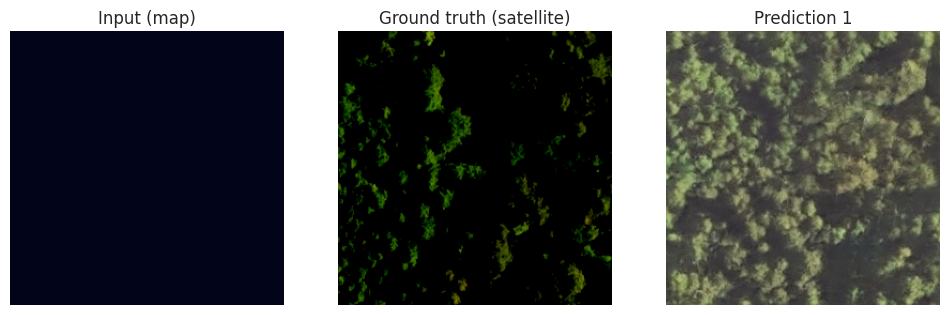

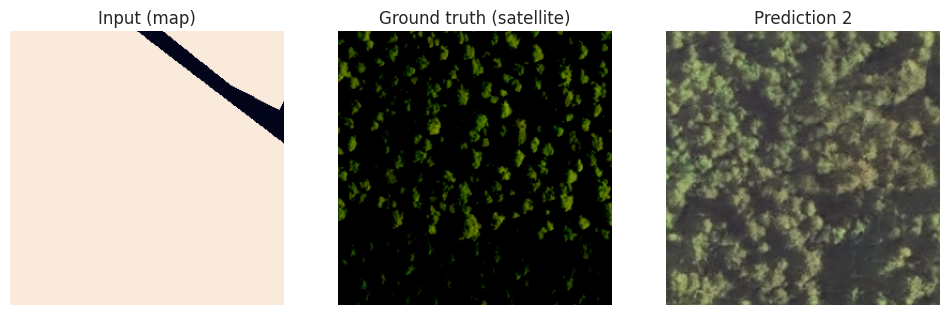

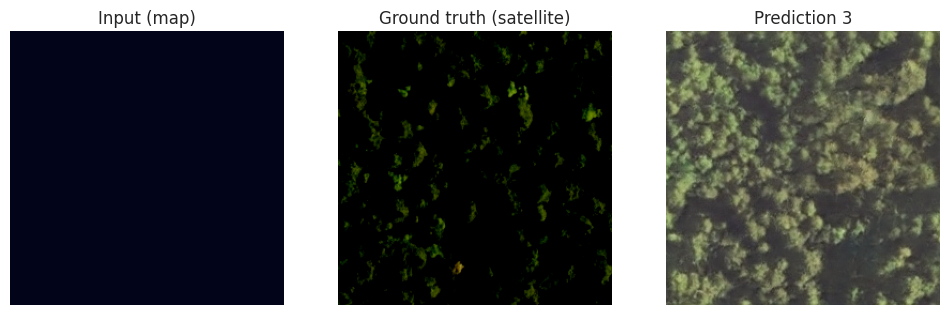

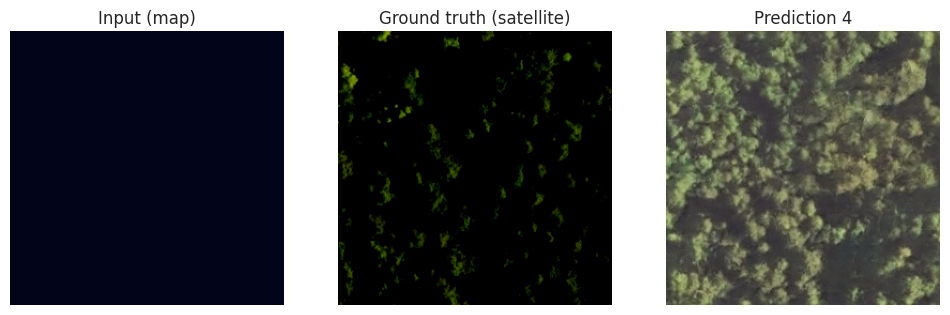

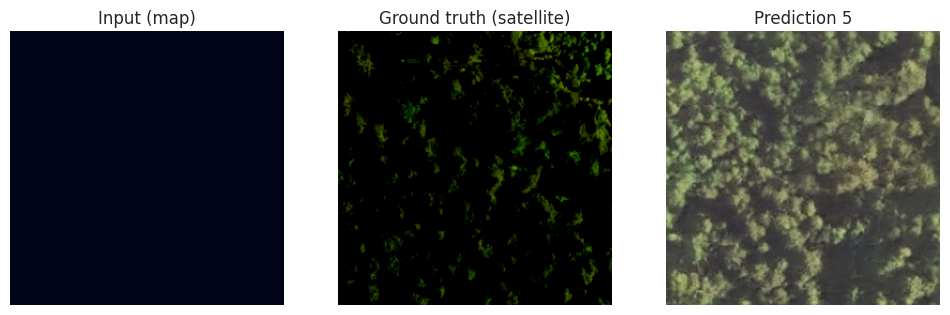

...

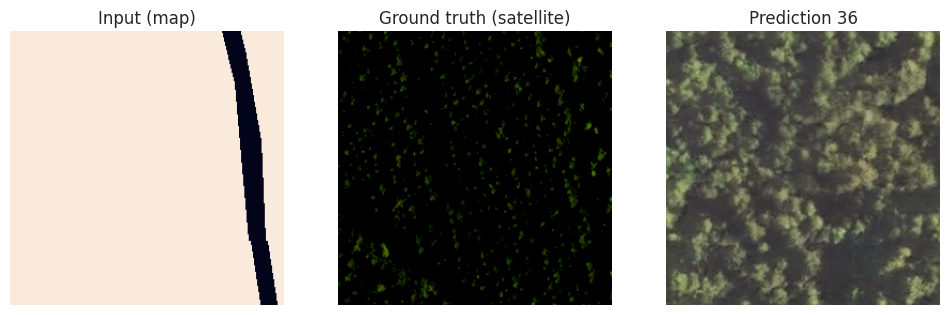

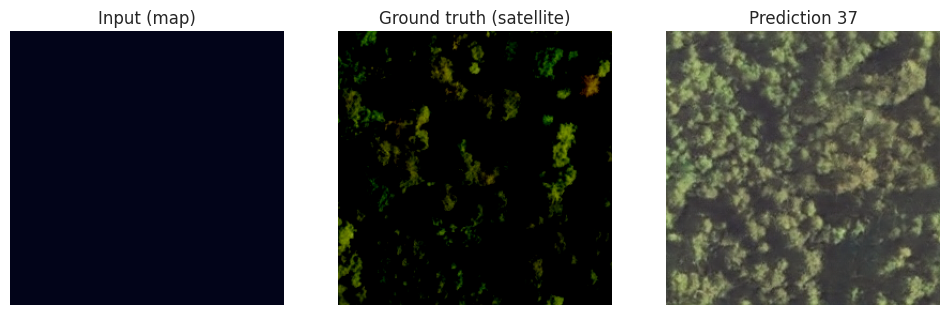

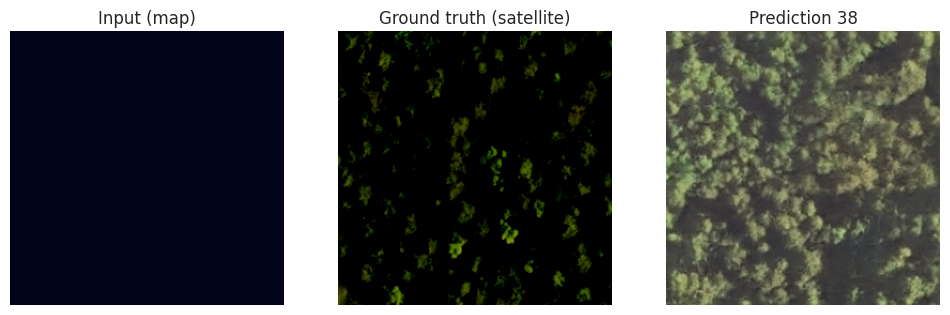

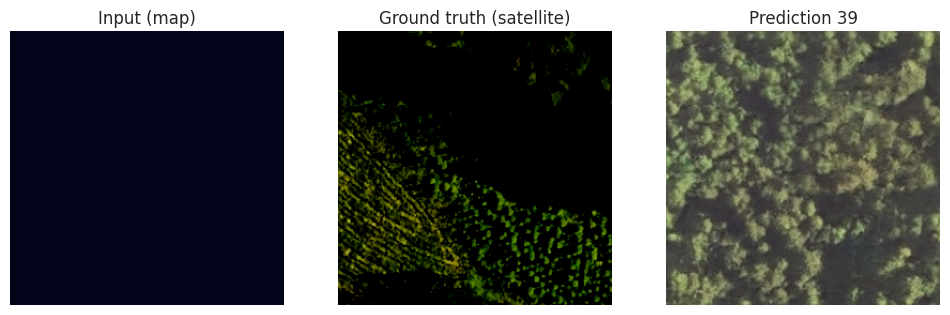

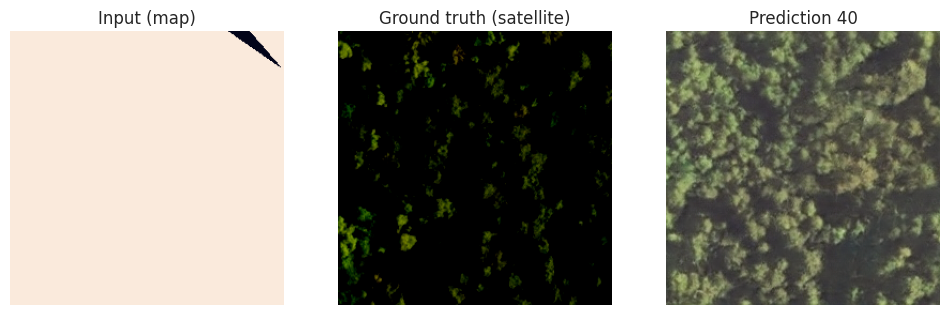

In [81]:
#Inspiration
show_predictions_simple(40)

**Chargement modèles pour inférence uniquement**

In [ ]:
# Charger le dernier bon modèle pour tester
load_models(generator, discriminator, epoch=200, prefix="landcover-L1-20-4000images")

generator.eval()
# ... ensuite appeler show_predictions() ou générer de nouvelles images ...

NameError: name 'load_models' is not defined

In [ ]:
save_models(generator, discriminator, epoch, prefix="landcover-L1-100-LSGAN-4000images")

Modèles sauvegardés → /content/drive/MyDrive/Pix2PixGANSatelliteMap/models/landcover-L1-100-LSGAN-4000images_epoch_0499.pth


In [ ]:
save_models(generator, discriminator, 500, prefix="landcover-L1-20-4000images")

Modèles sauvegardés → /content/drive/MyDrive/Pix2PixGANSatelliteMap/models/landcover-L1-20-4000images_epoch_0500.pth


**Show predictions for specific maps**

In [ ]:
#cette fonction affiche des prédictions pour des entrées spécifiques
@torch.no_grad()
def show_predictions_arbitrary():
    generator.eval()

    indices = [0,1,17,20,29,5,6,7]

#visualize_dataset(num_samples = 8, w = 12, h = 12, pad = 1.4,
#                 save_title = "Visualize_dataset", indices = [0,1,17,20,29,5,6,7])

    for idx in indices:
    #for i in range(num_samples):
        cond = condition[idx].unsqueeze(0).to(device)      # 1,C,H,W
        real = target[idx]                                 # C,H,W

        pred = generator(cond)[0].cpu()                    # C,H,W

        # Conversion pour matplotlib (H,W,C) + [0,1]
        cond_img = cond[0].cpu().permute(1,2,0).numpy()
        real_img = real.permute(1,2,0).numpy()
        pred_img = ((pred + 1) / 2).clamp(0,1).permute(1,2,0).numpy()

        plt.figure(figsize=(12, 4))

        plt.subplot(1, 3, 1)
        plt.imshow(np.clip(cond_img, 0, 1))
        plt.title("Input (map)")
        plt.axis('off')

        plt.subplot(1, 3, 2)
        plt.imshow(np.clip(real_img, 0, 1))
        plt.title("Ground truth (satellite)")
        plt.axis('off')

        plt.subplot(1, 3, 3)
        plt.imshow(pred_img)
        plt.title(f"Prediction {i+1}")
        plt.axis('off')



        plt.show()

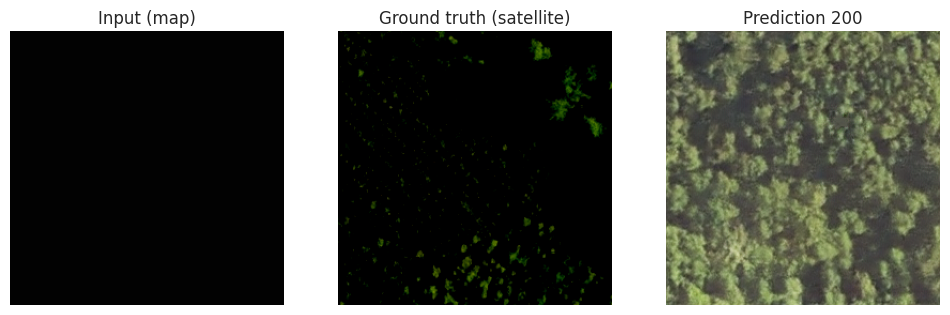

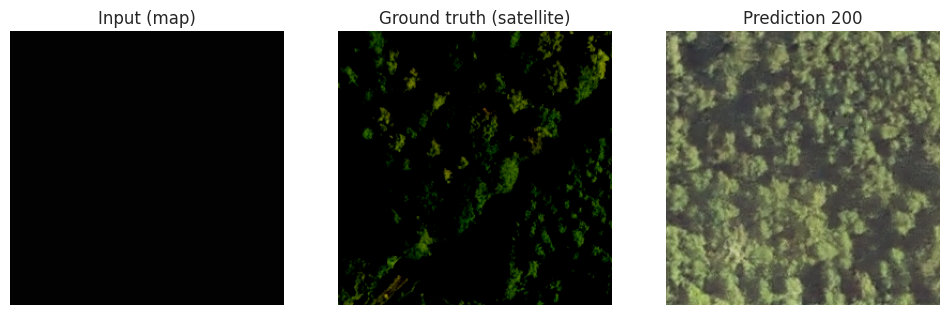

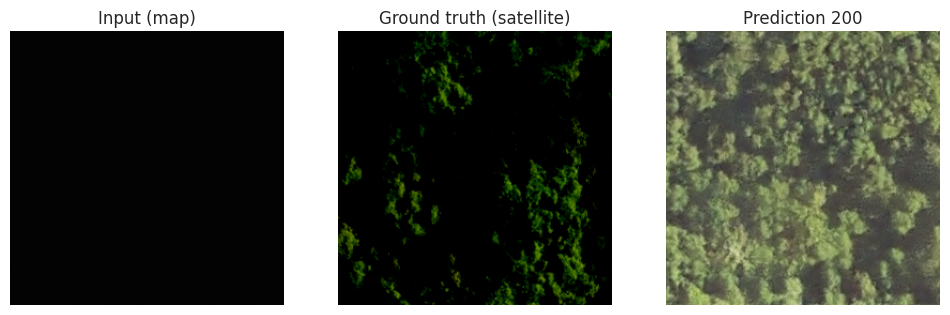

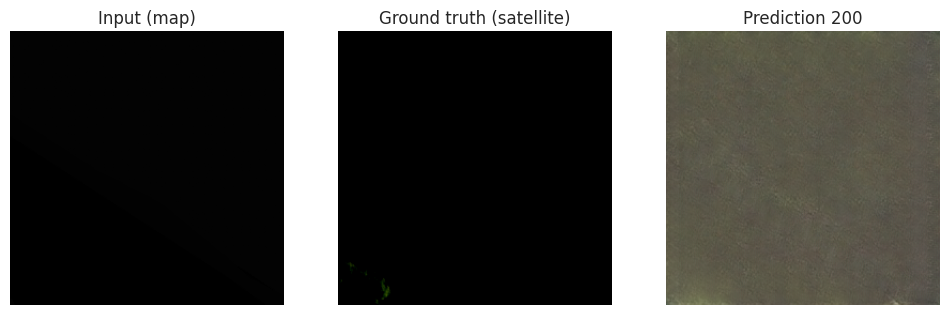

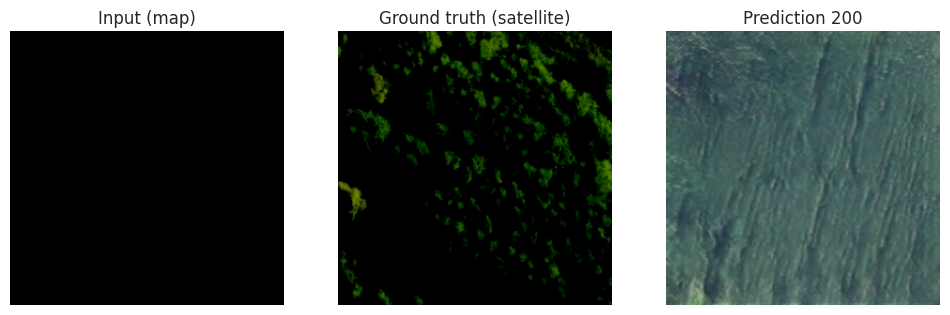

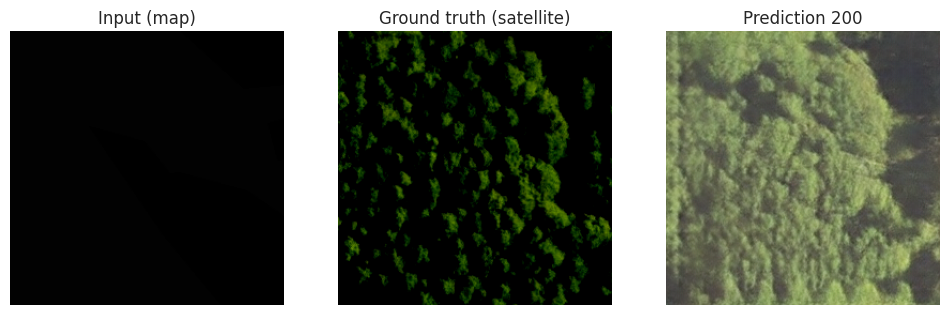

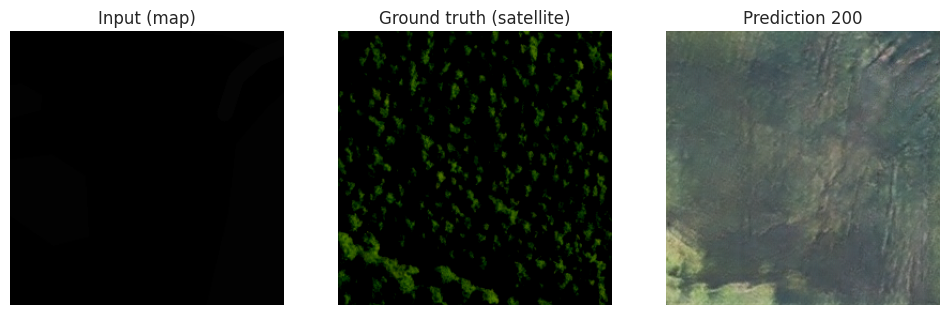

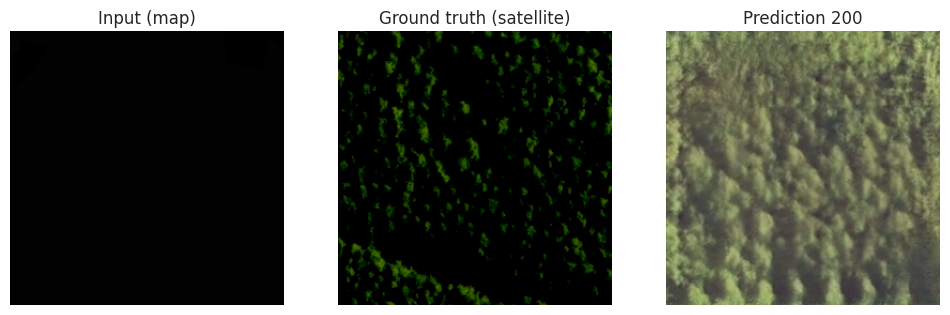

In [ ]:
#Ici on affiche les prédictions pour des cartes spécifiques du dataset
show_predictions_arbitrary()

**Recherche de carte avec éléments d'annotation**

In [53]:
#cette fonction affiche des prédictions pour des entrées spécifiques
@torch.no_grad()
def show_maps():
    generator.eval()
    ncols = 3
    nbimage = 200
    nrows = -(-nbimage // ncols)           # arrondi supérieur = 34
    fig, ax = plt.subplots(nrows, ncols, figsize=(9, 2.3 * nrows))
    ax = ax.ravel()   # aplatit en 1D

    for idx in range(1,nbimage):
      cond = condition[idx].unsqueeze(0).to(device)      # 1,C,H,W
      # Conversion pour matplotlib (H,W,C) + [0,1]
      #cond_img = (cond[0].cpu().permute(1,2,0).numpy()* 255).astype(np.uint8)
      #cond_img = cond[0, 0].cpu().numpy()
      cond_img = (cond[0, 0].cpu().numpy() * 255).astype(np.uint8)

      print(cond_img.min(), cond_img.max(), cond_img.dtype)
      #ax[idx].imshow(cond_img)
      ax[idx].imshow(cond_img,cmap = labels_cmap, interpolation = None,
                            vmin = -0.5, vmax = 4.5 )
      ax[idx].axis('off')

    # masquer les axes non utilisés
    for i in range(nbimage, len(ax)):
        ax[i].set_axis_off()

    plt.tight_layout(pad=0.3)
    plt.show()

2 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
0 2 uint8
0 4 uint8
0 4 uint8
0 4 uint8
0 4 uint8
2 2 uint8
0 3 uint8
0 3 uint8
0 3 uint8
0 3 uint8
0 3 uint8
0 3 uint8
0 3 uint8
0 3 uint8
0 3 uint8
0 3 uint8
2 2 uint8
2 3 uint8
3 3 uint8
0 3 uint8
0 2 uint8
0 2 uint8
0 2 uint8
0 0 uint8
0 0 uint8
0 2 uint8
0 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
0 2 uint8
0 2 uint8
2 2 uint8
0 2 uint8
0 4 uint8
0 4 uint8
0 3 uint8
0 3 uint8
0 3 uint8
0 2 uint8
0 3 uint8
0 3 uint8
0 3 uint8
0 3 uint8
3 3 uint8
0 3 uint8
0 3 uint8
0 3 uint8
0 3 uint8
2 2 uint8
2 2 uint8
0 2 uint8
0 2 uint8
0 0 uint8
0 2 uint8
0 2 uint8
0 2 uint8
0 2 uint8
0 2 uint8
0 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
0 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
2 2 uint8
0 4 uint8
0 4 uint8
0 3 uint8
0 3 uint8
0 3 uint8
0 3 uint8
0 3 uint8
0 3 uint8
0 2 uint8
0 3 uint8
3 3 uint8
0 3 uint8
0 3 uint8
0 2 uint8





In [54]:
show_maps()